# 03 - Estadística descriptiva y distribuciones (histórico 2012-2022)

Completa el *data understanding* sobre `accidentes_historico_2012_2022.csv`
(única fuente con `gravedad`, por lo tanto la del target `es_incapacitante`):
estadística descriptiva por tipo de variable, distribuciones y análisis de
valores faltantes. Es el paso previo a *data preparation*.

Parte de `data/processed/` y solo importa y muestra: la lógica vive en
`src/eda.py`. No se muestra ninguna columna de texto libre
(`descripcion_accidente`) por confidencialidad. Este notebook no modifica ni
imputa datos: solo describe.

In [1]:
import sys
from pathlib import Path

import pandas as pd
import seaborn as sns

sys.path.append(str(Path.cwd().parent))

from src.config import FIGURES_DIR, PROCESSED_DIR
from src.eda import (
    describe_categorical,
    describe_numeric,
    nulos_por_anio,
    plot_barras_categoricas,
    plot_histogramas,
    plot_nulos,
    plot_nulos_por_anio,
)

sns.set_theme()
pd.set_option("display.width", 200)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(PROCESSED_DIR / "accidentes_historico_2012_2022.csv", parse_dates=["fecha_evento"])

COLS_NUM_X = ["edad_anios", "experiencia_puesto_meses", "anio"]
COLS_CAT_X = ["sexo", "turno", "mes", "area_responsabilidad", "programa", "actividad_realizada",
              "puesto_trabajo", "lugar", "fuente_peligro"]

print("shape:", df.shape)
print("años:", df["anio"].min(), "-", df["anio"].max())
print("tipos:", df.dtypes.value_counts().to_dict())

shape: (1028, 28)
años: 2012 - 2022
tipos: {<StringDtype(na_value=nan)>: 19, dtype('float64'): 7, dtype('<M8[ns]'): 1, dtype('int64'): 1}


## 1. Variables numéricas

`edad_anios`, `experiencia_puesto_meses` y `anio` son las X numéricas.
`dias_perdidos` se incluye solo como referencia: es *data leakage* (se conoce
después del evento) y no es X.

In [2]:
describe_numeric(df, COLS_NUM_X + ["dias_perdidos"])

,n,pct_nulos,media,desviacion,min,p5,p25,mediana,p75,p95,max,asimetria
edad_anios,643.0,37.5,34.85,11.53,18.0,19.0,25.0,34.0,43.0,55.0,63.0,0.41
experiencia_puesto_meses,644.0,37.4,61.10,82.81,0.0,0.5,4.0,21.0,96.0,216.0,492.0,1.96
anio,1028.0,0.0,2017.99,2.96,2012.0,2013.0,2016.0,2019.0,2020.0,2022.0,2022.0,-0.53
dias_perdidos,911.0,11.4,24.50,152.63,0.0,0.0,3.0,7.0,19.0,90.0,4500.0,27.82


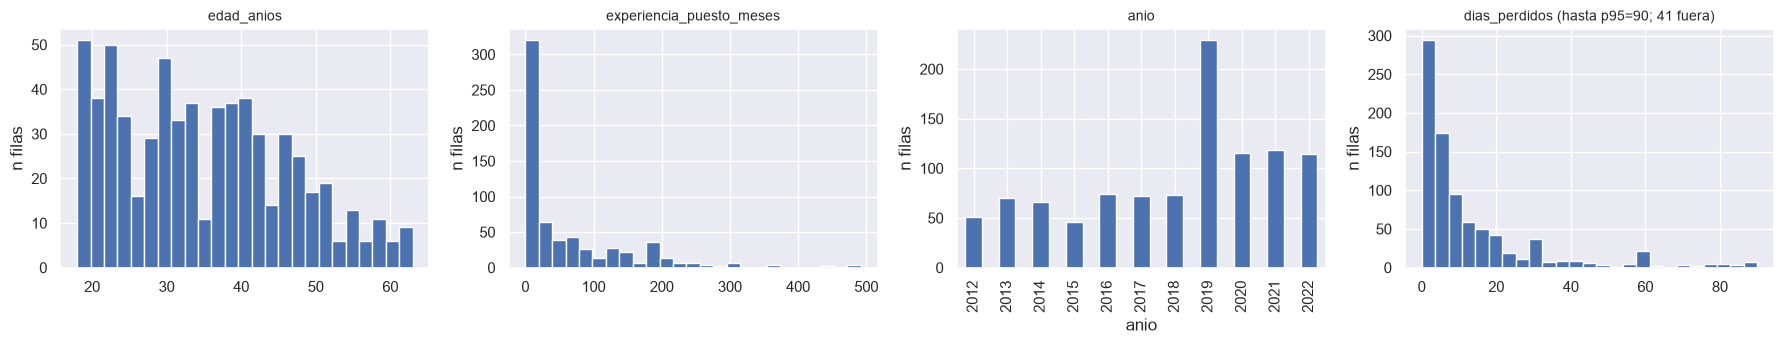

In [3]:
fig = plot_histogramas(df, COLS_NUM_X + ["dias_perdidos"], recortar_p95=("dias_perdidos",))
fig.savefig(FIGURES_DIR / "descriptiva_histogramas_numericas.png", dpi=100)

### Hallazgo

- **`edad_anios`** (n=643): media 34.8, mediana 34, rango 18-63 (p5-p95: 19-55).
  Asimetría 0.41: distribución casi simétrica, con una cola leve hacia edades altas.
- **`experiencia_puesto_meses`** (n=644): mediana 21 meses (≈1.8 años) contra
  media 61 (≈5.1 años); asimetría 1.96. El 25% de los casos tiene 4 meses o menos
  de experiencia y el p95 llega a 216 meses (máximo 492): mayoría de casos con poca
  experiencia y una cola larga de trabajadores antiguos.
- **`anio`**: 2019 concentra 229 registros (22% del total), contra 46-74 por año en
  2012-2018 y ~115 por año en 2020-2022.
- **`dias_perdidos`** (referencia, no es X; n=911): mediana 7 días, p95 90, pero media
  24.5 y máximo 4500 (asimetría 27.8). Un solo valor extremo distorsiona media y
  desviación; 61 registros tienen 0 días.

## 2. Variables categóricas

Frecuencias, categoría dominante y cardinalidad de las X categóricas.

In [4]:
describe_categorical(df, COLS_CAT_X)

,pct_nulos,n_categorias,categoria_dominante,pct_dominante,categorias_con_1_caso
sexo,34.1,3,M,84.8,0
turno,9.6,6,DIA,35.0,0
mes,0.0,13,ENERO,10.6,0
area_responsabilidad,49.2,23,PRODUCCION,48.3,9
programa,20.7,75,GALLETERA LIMA,14.2,27
actividad_realizada,1.8,70,DURANTE OPERACION PRODUCTIVA,27.9,36
puesto_trabajo,5.6,344,PERSONAL ALICORP,10.3,256
lugar,6.0,371,COPSA,6.3,287
fuente_peligro,4.8,359,EQUIPO,12.5,270


In [5]:
print("sexo:", df["sexo"].value_counts(dropna=False).to_dict())
print("turno:", df["turno"].value_counts(dropna=False).to_dict())
print("mes:", df["mes"].value_counts().to_dict())

sexo: {'M': 574, nan: 351, 'F': 98, '-': 5}
turno: {'DIA': 325, 'TARDE': 224, 'NOCHE': 140, 'TURNO_1': 119, nan: 99, 'TURNO_2': 76, 'TURNO_3': 45}
mes: {'ENERO': 109, 'MARZO': 107, 'NOVIEMBRE': 102, 'AGOSTO': 97, 'FEBRERO': 93, 'OCTUBRE': 87, 'JULIO': 82, 'JUNIO': 74, 'MAYO': 73, 'ABRIL': 68, 'DICIEMBRE': 58, 'SETIEMBRE': 44, 'SEPTIEMBRE': 34}


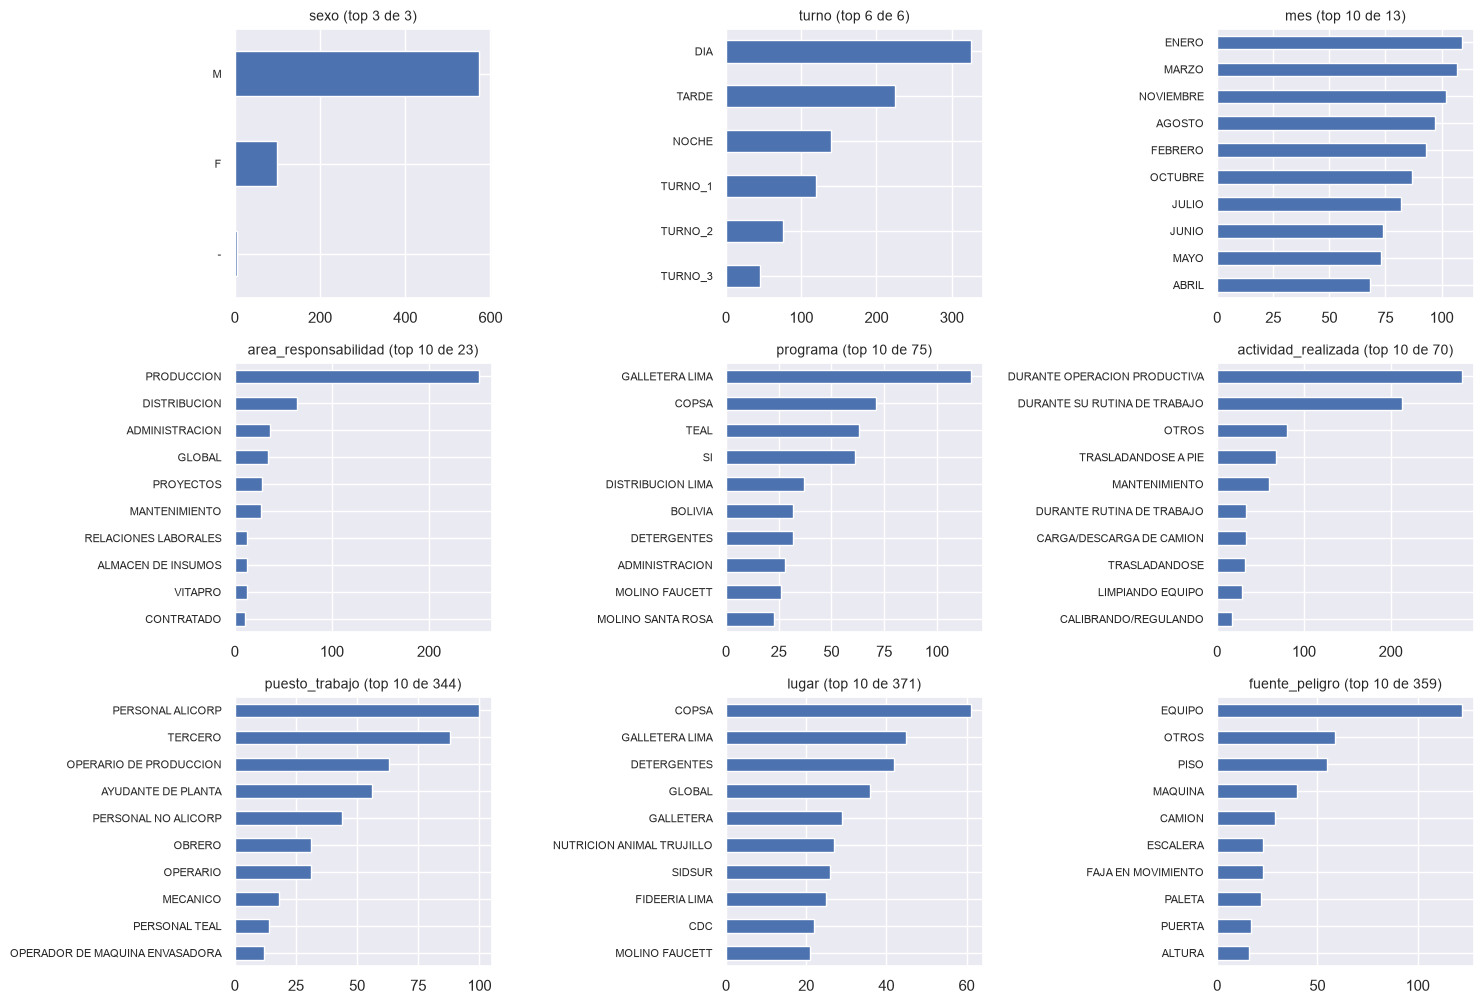

In [6]:
fig = plot_barras_categoricas(df, COLS_CAT_X)
fig.savefig(FIGURES_DIR / "descriptiva_barras_categoricas.png", dpi=100)

### Hallazgo

- **`sexo`**: 34.1% de nulos. Entre los no nulos, 84.8% es `M`, 14.5% `F` y 5 filas
  traen `"-"`.
- **`turno`**: `DIA` es la categoría dominante (35.0%). Conviven dos esquemas: franja
  horaria (`DIA`/`TARDE`/`NOCHE`, 689 filas) y turno numerado (`TURNO_1/2/3`, 240 filas).
- **`mes`**: 13 categorías en lugar de 12: `SETIEMBRE` (44) y `SEPTIEMBRE` (34) son el mismo
  mes con dos grafías. `ENERO` (10.6%) y `MARZO` son los de mayor frecuencia.
- **`area_responsabilidad`**: 49.2% de nulos; `PRODUCCION` reúne el 48.3% de los no nulos.
- **`actividad_realizada`**: `DURANTE OPERACION PRODUCTIVA` domina (27.9%). Aparecen como
  categorías separadas `DURANTE SU RUTINA DE TRABAJO` y `DURANTE RUTINA DE TRABAJO`.
- **Alta cardinalidad**: `puesto_trabajo` (344 categorías), `lugar` (371) y `fuente_peligro`
  (359) tienen entre 74% y 77% de sus categorías con un único registro, y su categoría
  dominante no supera el 12.5%. En `puesto_trabajo` las más frecuentes son genéricas
  (`PERSONAL ALICORP`, `TERCERO`).

## 3. Valores faltantes

Porcentaje de nulos por columna (línea roja: umbral de 80% usado en el
diccionario de datos) y su distribución por año.

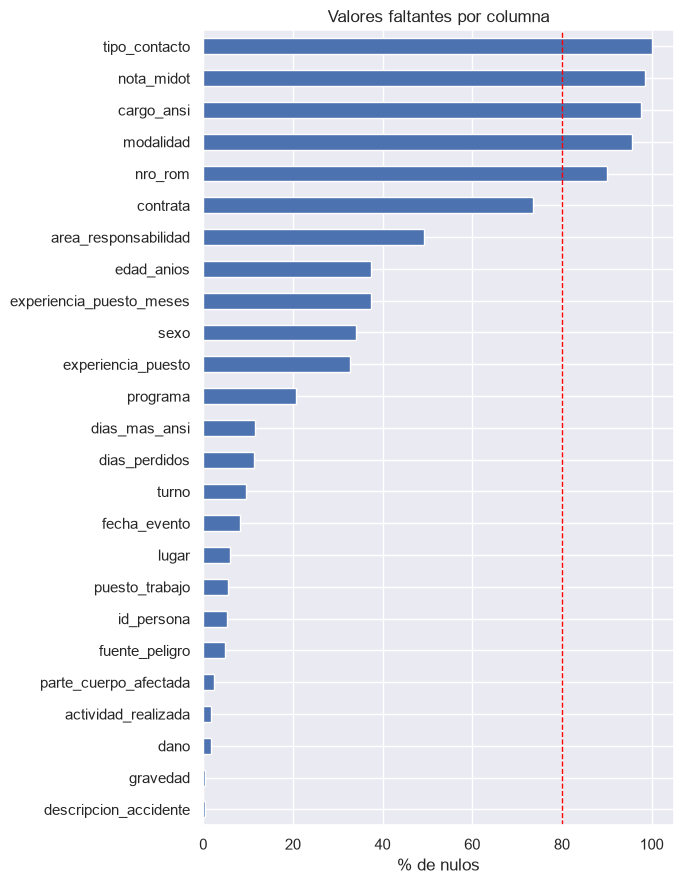

In [7]:
fig = plot_nulos(df)
fig.savefig(FIGURES_DIR / "descriptiva_nulos_por_columna.png", dpi=100)

In [8]:
COLS_NULOS_ANIO = ["edad_anios", "experiencia_puesto_meses", "sexo", "turno", "programa",
                   "area_responsabilidad", "fecha_evento"]
tabla_nulos = nulos_por_anio(df, COLS_NULOS_ANIO)
print("filas por año:", df["anio"].value_counts().sort_index().to_dict())
tabla_nulos

filas por año: {2012: 51, 2013: 70, 2014: 66, 2015: 46, 2016: 74, 2017: 72, 2018: 73, 2019: 229, 2020: 115, 2021: 118, 2022: 114}


,edad_anios,experiencia_puesto_meses,sexo,turno,programa,area_responsabilidad,fecha_evento
anio,,,,,,,
2012,37.0,41.0,37.0,37.0,100.0,2.0,0.0
2013,51.0,49.0,44.0,46.0,100.0,0.0,0.0
2014,42.0,32.0,6.0,8.0,50.0,0.0,71.0
2015,13.0,91.0,2.0,4.0,2.0,0.0,48.0
2016,14.0,19.0,0.0,12.0,73.0,0.0,11.0
2017,10.0,14.0,0.0,0.0,0.0,0.0,1.0
2018,22.0,15.0,1.0,1.0,0.0,0.0,3.0
2019,32.0,66.0,2.0,3.0,2.0,77.0,0.0
2020,63.0,39.0,56.0,5.0,0.0,90.0,3.0


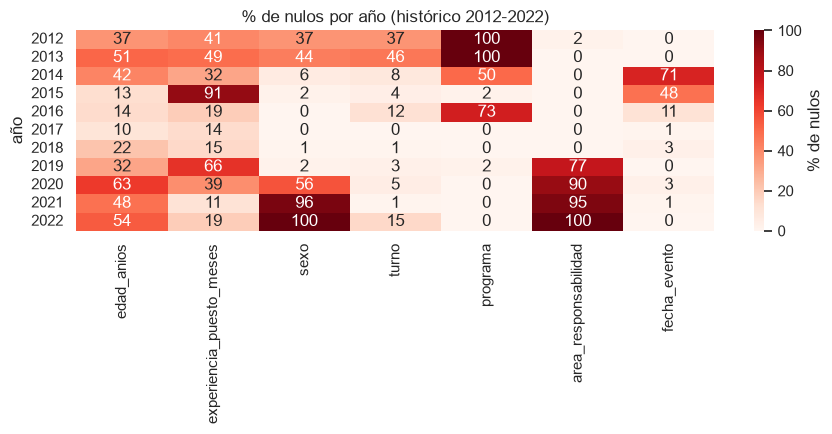

In [9]:
fig = plot_nulos_por_anio(tabla_nulos)
fig.savefig(FIGURES_DIR / "descriptiva_nulos_por_anio.png", dpi=100)

### Hallazgo

- **Más del 80% de nulos**: `tipo_contacto` (100%), `nota_midot`, `cargo_ansi`, `modalidad`
  y `nro_rom` (90%). `contrata` está en 73%.
- **Nulos en las X**: `area_responsabilidad` 49.2%, `edad_anios` 37.5%,
  `experiencia_puesto_meses` 37.4%, `sexo` 34.1%, `programa` 20.7% y `turno` 9.6%.
  `mes` y `anio` no tienen nulos.
- **Los nulos no son aleatorios: dependen del año.**
  - `sexo`: ≤6% en 2014-2019, pero 56% en 2020, 96% en 2021 y 100% en 2022.
  - `area_responsabilidad`: ≤2% en 2012-2018, luego 77% (2019), 90%, 95% y 100% (2022).
  - `programa`: 100% nulo en 2012-2013, 50% en 2014 y 73% en 2016; ≤2% el resto.
  - `edad_anios`: 37-63% en 2012-2014 y 2020-2022, contra 10-22% en 2015-2018.
  - `fecha_evento`: los nulos se concentran en 2014 (71%) y 2015 (48%).

## Puntos a decidir en Data Preparation

Lo observado deja estos puntos abiertos; ninguno se resuelve aquí (no se imputa ni
recodifica nada sin decisión del equipo, ver CLAUDE.md):

1. **Grafías duplicadas**: unificar `SETIEMBRE`/`SEPTIEMBRE` en `mes` y revisar las
   variantes de `actividad_realizada`.
2. **`sexo`**: 5 filas con `"-"` (en `turno` y `gravedad` ese marcador ya se trata como nulo).
3. **Nulos por año** en `sexo`, `area_responsabilidad` y `programa`: definir cómo tratarlos.
   Cualquier partición temporal de entrenamiento y prueba deja estas columnas casi vacías
   en los años recientes.
4. **Alta cardinalidad** de `puesto_trabajo`, `lugar` y `fuente_peligro`: definir codificación
   y agrupamiento (diferido antes por falta de criterio de dominio).
5. **`experiencia_puesto_meses`**: asimetría de 1.96; evaluar una transformación.
6. **Año 2019** (22% de los registros): confirmar con SST si hubo un cambio de criterio de
   registro (hipótesis de la Pregunta 5 en `02_eda_dirigido`).
7. **Columnas con más de 80% de nulos**: decidir su exclusión del dataset de modelado.